# Entraîner et tester deux modèles de prévision des ventes

La cible est la quantité vendue brute d’un produit par jour. Ce notebook entraîne un LSTM compact et un Transformer Encoder minimal, puis les compare à une baseline.

## Découpage temporel
- Le notebook ne lit que `online_retail_actuel.xlsx`, jusqu’au **30 septembre 2011 inclus**.
- Les données jusqu’au 31 août servent à l’entraînement ; septembre est réservé au test chronologique.
- Les ventes après septembre ne sont pas disponibles à ce stade ; elles seront traitées plus tard lorsqu’elles arriveront via PUSH ou PULL.
- Pour chaque produit, les jours sans vente après sa première transaction valent zéro.
- Chaque fenêtre de test utilise seulement les 100 jours qui précèdent sa date cible.

Le test de septembre est une validation historique ; les données postérieures à septembre ne sont pas chargées dans ce notebook.

## 0. Environnement

Le notebook suppose que le répertoire courant contient online_retail_actuel.xlsx.

In [19]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| appareil:", DEVICE)

PyTorch: 2.15.0+cu132 | appareil: cuda


## 1. Chargeons les données utiles

Une ligne source décrit un article sur une facture. Les identifiants sont conservés comme texte et la date est convertie explicitement.

In [20]:
required_columns = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate"]
current_path = Path("online_retail_actuel.xlsx")
if not current_path.exists():
    raise FileNotFoundError("online_retail_actuel.xlsx absent. Lance Jupyter depuis le dossier projet.")

raw = pd.read_excel(current_path, engine="openpyxl", usecols=required_columns)
raw["InvoiceNo"] = raw["InvoiceNo"].astype("string").str.strip()
raw["StockCode"] = raw["StockCode"].astype("string").str.strip()
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], errors="coerce")
raw["Quantity"] = pd.to_numeric(raw["Quantity"], errors="coerce")
raw = raw.dropna(subset=required_columns).copy()
raw["Quantity"] = raw["Quantity"].astype("int64")
history_end = pd.Timestamp("2011-09-30")
assert raw["InvoiceDate"].max().normalize() <= history_end
print("Fichier actuel :", raw.shape, "|", raw["InvoiceDate"].min(), "→", raw["InvoiceDate"].max())
display(raw.dtypes.to_frame("type"))
display(raw.head())

Fichier actuel : (370931, 4) | 2010-12-01 08:26:00 → 2011-09-30 17:22:00


,type
InvoiceNo,string
StockCode,string
Quantity,int64
InvoiceDate,datetime64[us]


,InvoiceNo,StockCode,Quantity,InvoiceDate
0,536365,85123A,6,2010-12-01 08:26:00
1,536365,71053,6,2010-12-01 08:26:00
2,536365,84406B,8,2010-12-01 08:26:00
3,536365,84029G,6,2010-12-01 08:26:00
4,536365,84029E,6,2010-12-01 08:26:00


## 2. Construisons la cible brute produit × jour

On exclut les factures dont le numéro commence par C, ainsi que les quantités nulles ou négatives. Cela suit le choix métier retenu : compter les ventes positives sans soustraire les retours.

In [21]:
CUTOFF = history_end
TRAIN_END = pd.Timestamp("2011-08-31")
LOOKBACK = 100
TOP_N = 10

raw["is_cancellation"] = raw["InvoiceNo"].str.upper().str.startswith("C", na=False)
raw["gross_line_quantity"] = raw["Quantity"].where(
    (~raw["is_cancellation"]) & (raw["Quantity"] > 0), 0
)
raw["day"] = raw["InvoiceDate"].dt.normalize()

daily_product = (
    raw.groupby(["StockCode", "day"], as_index=False)["gross_line_quantity"]
       .sum()
       .rename(columns={"gross_line_quantity": "gross_quantity"})
)
history_observed = daily_product[daily_product["day"] <= TRAIN_END]

# Le top 10 est sélectionné sur l'entraînement uniquement ; septembre reste hors sélection.
product_totals = history_observed.groupby("StockCode")["gross_quantity"].sum()
product_first_day = history_observed.groupby("StockCode")["day"].min()
eligible_products = product_totals[product_first_day.reindex(product_totals.index) <= CUTOFF]
selected_products = eligible_products.sort_values(ascending=False).head(TOP_N).index.tolist()
if len(selected_products) < TOP_N:
    raise ValueError(f"Seulement {len(selected_products)} produits éligibles.")

display(product_totals.loc[selected_products].sort_values(ascending=False).rename(
    "ventes_brutes_avant_cutoff"
).to_frame())

,ventes_brutes_avant_cutoff
StockCode,
23166,76571
84077,37426
85123A,31772
85099B,31651
22197,28141
21212,27830
84879,24053
15036,21411
22616,19581


## 3. Formons les calendriers quotidiens

Chaque série commence à la première transaction du produit dans le fichier actuel. Les jours sans vente jusqu’au 30 septembre sont complétés par zéro. Le test est une période réservée à l’intérieur de ce même fichier ; aucune donnée future n’est chargée.

In [22]:
future_end = history_end
series = {}

for product in selected_products:
    first_day = product_first_day.loc[product]
    calendar = pd.date_range(first_day, future_end, freq="D", name="day")
    product_values = daily_product.loc[daily_product["StockCode"].eq(product)].set_index("day")["gross_quantity"]
    series[product] = product_values.reindex(calendar, fill_value=0).astype("float32")

history_by_product = {p: s.loc[:CUTOFF].copy() for p, s in series.items()}

summary = pd.DataFrame({
    "premier_jour": {p: s.index.min() for p, s in history_by_product.items()},
    "jours_historique": {p: len(s) for p, s in history_by_product.items()},
    "ventes_brutes_historique": {p: s.sum() for p, s in history_by_product.items()},
})
display(summary)
if any(len(s) <= LOOKBACK for s in history_by_product.values()):
    raise ValueError("Un produit ne possède pas 100 jours historiques avant la coupure.")

,premier_jour,jours_historique,ventes_brutes_historique
23166,2011-01-18,256,76917.0
84077,2010-12-02,303,40941.0
85123A,2010-12-01,304,34250.0
85099B,2010-12-01,304,36052.0
22197,2010-12-01,304,32337.0
21212,2010-12-01,304,31256.0
84879,2010-12-01,304,27117.0
15036,2010-12-02,303,21898.0
22616,2010-12-01,304,21181.0
21977,2010-12-01,304,21773.0


## 4. Préparons les fenêtres de 100 jours

Chaque exemple contient les 100 jours précédents, le code du produit et la quantité du jour suivant comme cible. Chaque `StockCode` sélectionné reçoit un indice entier stable, utilisé pour retrouver son embedding. Conservons ce dictionnaire avec les modèles pour les réutiliser à l’inférence. Les cibles jusqu’au 31 août servent à l’entraînement ; septembre est gardé pour le test. La normalisation est ajustée sur l’entraînement seulement.

In [23]:
def make_windows(values, lookback=LOOKBACK):
    values = np.asarray(values, dtype=np.float32)
    X, y = [], []
    for target_index in range(lookback, len(values)):
        X.append(values[target_index - lookback:target_index])
        y.append(values[target_index])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

X_parts, y_parts, product_parts, date_parts = [], [], [], []
for product, values in history_by_product.items():
    X_p, y_p = make_windows(values.to_numpy())
    X_parts.append(X_p)
    y_parts.append(y_p)
    product_parts.extend([product] * len(y_p))
    date_parts.extend(values.index[LOOKBACK:])

X_raw = np.concatenate(X_parts)
y_raw = np.concatenate(y_parts)
sample_products = np.asarray(product_parts)
product_to_index = {product: index for index, product in enumerate(selected_products)}
product_indices = np.asarray([product_to_index[p] for p in sample_products], dtype=np.int64)
print("Correspondance StockCode → indice :", product_to_index)
sample_dates = pd.DatetimeIndex(date_parts)
train_mask = sample_dates < pd.Timestamp("2011-09-01")
validation_mask = (sample_dates >= pd.Timestamp("2011-09-01")) & (sample_dates <= CUTOFF)
if not train_mask.any() or not validation_mask.any():
    raise ValueError("La séparation chronologique entraînement/validation est vide.")

y_log = np.log1p(y_raw)
Y_MEAN = float(y_log[train_mask].mean())
Y_STD = float(y_log[train_mask].std()) or 1.0
X_scaled = (np.log1p(X_raw) - Y_MEAN) / Y_STD
y_scaled = (y_log - Y_MEAN) / Y_STD
print("Fenêtres d’entraînement :", int(train_mask.sum()))
print("Fenêtres de test en septembre :", int(validation_mask.sum()))
print("Dates test :", sample_dates[validation_mask].min().date(), "→", sample_dates[validation_mask].max().date())

Correspondance StockCode → indice : {'23166': 0, '84077': 1, '85123A': 2, '85099B': 3, '22197': 4, '21212': 5, '84879': 6, '15036': 7, '22616': 8, '21977': 9}
Fenêtres d’entraînement : 1690
Fenêtres de test en septembre : 300
Dates test : 2011-09-01 → 2011-09-30


## 5. Définissons les deux réseaux compacts

Chaque modèle reçoit deux entrées : les quantités `(taille_lot, 100, 1)` et un indice produit par exemple `(taille_lot,)`. Un embedding appris transforme chaque indice en vecteur de 4 valeurs `(taille_lot, 4)`. Après traitement des 100 jours, ce vecteur est concaténé à la représentation de la série pour prévoir une quantité par exemple : sortie `(taille_lot,)`. Les poids du LSTM et du Transformer, y compris leurs embeddings, sont distincts. Les produits inconnus ne sont pas pris en charge dans cette première version.

In [24]:
class SmallLSTM(nn.Module):
    def __init__(self, num_products, hidden_size=16, embedding_size=4):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_size, batch_first=True)
        self.product_embedding = nn.Embedding(num_products, embedding_size)
        self.head = nn.Linear(hidden_size + embedding_size, 1)

    def forward(self, x, product_ids):
        sequence, _ = self.lstm(x)
        product_features = self.product_embedding(product_ids)
        features = torch.cat((sequence[:, -1, :], product_features), dim=1)
        return self.head(features).squeeze(-1)


class SmallTransformer(nn.Module):
    def __init__(self, num_products, lookback=LOOKBACK, d_model=16, nhead=2, embedding_size=4):
        super().__init__()
        self.input_projection = nn.Linear(1, d_model)
        self.position = nn.Parameter(torch.zeros(1, lookback, d_model))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=32,
            dropout=0.0, batch_first=True, activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.product_embedding = nn.Embedding(num_products, embedding_size)
        self.head = nn.Linear(d_model + embedding_size, 1)

    def forward(self, x, product_ids):
        x = self.input_projection(x) + self.position
        encoded = self.encoder(x)
        product_features = self.product_embedding(product_ids)
        features = torch.cat((encoded[:, -1, :], product_features), dim=1)
        return self.head(features).squeeze(-1)


lstm_model = SmallLSTM(num_products=len(product_to_index)).to(DEVICE)
transformer_model = SmallTransformer(num_products=len(product_to_index)).to(DEVICE)
print("Paramètres LSTM:", sum(p.numel() for p in lstm_model.parameters()))
print("Paramètres Transformer:", sum(p.numel() for p in transformer_model.parameters()))

Paramètres LSTM: 1277
Paramètres Transformer: 3917


## 6. Entraînons les modèles

Les réseaux n’apprennent qu’avec les fenêtres dont la cible précède septembre. Les hyperparamètres sont volontairement fixes : 60 époques, lots de 4, Adam et MSE sur la cible transformée. On choisi un batchsize petit car on a pas assez 

Entraînement: LSTM
Entraînement: Transformer


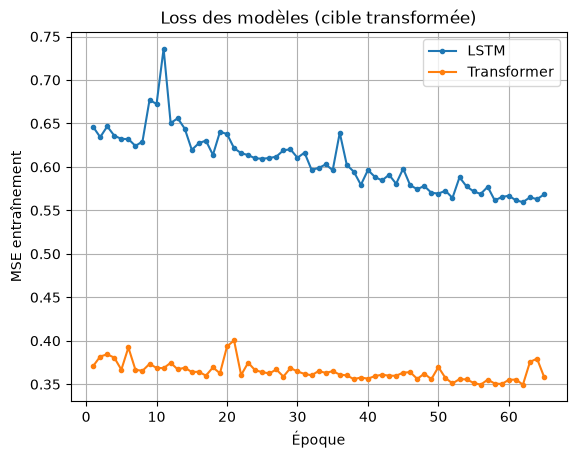

In [40]:
EPOCHS = 65
BATCH_SIZE = 32
LEARNING_RATE = 1e-3

train_dataset = TensorDataset(
    torch.tensor(X_scaled[train_mask, ..., None], dtype=torch.float32),
    torch.tensor(product_indices[train_mask], dtype=torch.long),
    torch.tensor(y_scaled[train_mask], dtype=torch.float32),
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

def fit_model(model, loader, epochs=EPOCHS):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss, count = 0.0, 0
        for batch_x, batch_products, batch_y in loader:
            batch_x, batch_products, batch_y = batch_x.to(DEVICE), batch_products.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(batch_x, batch_products), batch_y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_y)
            count += len(batch_y)
        losses.append(total_loss / count)
    return losses

loss_history = {}
for name, model in [("LSTM", lstm_model), ("Transformer", transformer_model)]:
    print("Entraînement:", name)
    loss_history[name] = fit_model(model, train_loader)

pd.DataFrame(loss_history, index=range(1, EPOCHS + 1)).plot(marker=".")
plt.xlabel("Époque")
plt.ylabel("MSE entraînement")
plt.title("Loss des modèles (cible transformée)")
plt.grid(True)
plt.show()

## 7. Définissons la baseline hebdomadaire

Pour prévoir le jour t, cette baseline moyenne les observations aux jours t−7, t−14, t−21 et t−28. Elle ne consulte que l’historique disponible avant la prédiction.

In [42]:
def predict_weekly_mean(history_values):
    if len(history_values) < 28:
        raise ValueError("La baseline nécessite au moins 28 jours d’historique.")
    # La dernière valeur connue est t-1 : on commence donc à l'index -7.
    previous_same_weekdays = np.asarray(history_values[-7::-7][:4], dtype=float)
    if len(previous_same_weekdays) != 4:
        raise ValueError("Il faut quatre jours précédents de même nom.")
    return max(0, int(np.rint(previous_same_weekdays.mean())))

def predict_neural(model, history_values, product):
    if product not in product_to_index:
        raise ValueError(f"Produit inconnu : {product}. Seuls les produits entraînés sont pris en charge.")
    recent = np.asarray(history_values[-LOOKBACK:], dtype=np.float32)
    if len(recent) != LOOKBACK:
        raise ValueError("Le réseau nécessite 100 jours d'historique.")
    scaled = (np.log1p(recent) - Y_MEAN) / Y_STD
    x = torch.tensor(scaled[None, :, None], dtype=torch.float32, device=DEVICE)
    product_id = torch.tensor([product_to_index[product]], dtype=torch.long, device=DEVICE)
    model.eval()
    with torch.no_grad():
        output_scaled = float(model(x, product_id).cpu().item())
    prediction = np.expm1(output_scaled * Y_STD + Y_MEAN)
    return max(0, int(np.rint(prediction)))

# Vérifie que la baseline utilise bien quatre valeurs séparées de sept jours.
example = list(range(1, 30))
assert predict_weekly_mean(example) == int(np.rint(np.mean([22, 15, 8, 1])))
print("Baseline vérifiée.")

Baseline vérifiée.


## 8. Testons chronologiquement sur septembre

Le test utilise uniquement des dates de septembre du fichier actuel. Pour chaque date, la prévision ne voit que les 100 jours précédents ; les ventes du jour cible ne sont jamais dans son entrée. Cette évaluation simule une prévision quotidienne, sans lire le fichier futur.

In [43]:
model_map = {"LSTM": lstm_model, "Transformer": transformer_model}
records = []
validation_indices = np.flatnonzero(validation_mask)
for index in validation_indices:
    product = sample_products[index]
    day = sample_dates[index]
    values = history_by_product[product]
    known_history = values.loc[values.index < day].astype(float).tolist()
    row = {
        "day": day,
        "StockCode": product,
        "actual": int(values.loc[day]),
        "baseline_4weeks": predict_weekly_mean(known_history),
    }
    for name, model in model_map.items():
        row[name] = predict_neural(model, known_history, product)
    records.append(row)

validation_results = pd.DataFrame(records).sort_values(["day", "StockCode"]).reset_index(drop=True)
print("Période de test :", validation_results["day"].min().date(), "→", validation_results["day"].max().date())
print("Prévisions produit-jour :", len(validation_results))
display(validation_results.head(12))

Période de test : 2011-09-01 → 2011-09-30
Prévisions produit-jour : 300


,day,StockCode,actual,baseline_4weeks,LSTM,Transformer
0,2011-09-01,15036,48,207,18,33
1,2011-09-01,21212,75,404,39,65
2,2011-09-01,21977,48,222,8,36
3,2011-09-01,22197,101,700,44,76
4,2011-09-01,22616,456,274,13,25
5,2011-09-01,23166,0,43,7,3
6,2011-09-01,84077,144,84,25,21
7,2011-09-01,84879,96,1216,28,64
8,2011-09-01,85099B,301,274,92,159
9,2011-09-01,85123A,112,78,40,87


## 9. Comparons sur la même période de test

Les métriques sont calculées sur les mêmes couples produit-jour de septembre. Les réseaux produisent des comptes arrondis et non négatifs. Une MAE plus basse est préférable ; les produits et la normalisation ont été déterminés sans utiliser les cibles de septembre.

,MAE_unités,RMSE_unités,nombre_prévisions
méthode,,,
Transformer,63.303,133.644,300
LSTM,64.260,133.677,300
baseline_4weeks,78.430,149.776,300


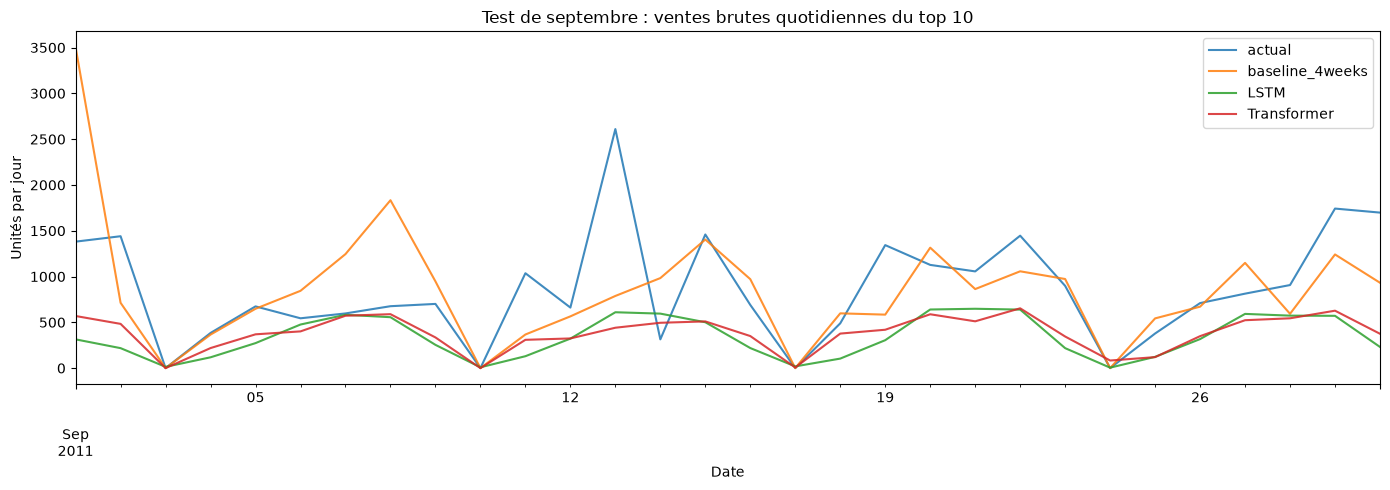

In [44]:
prediction_columns = ["baseline_4weeks", "LSTM", "Transformer"]
metric_rows = []
for name in prediction_columns:
    error = validation_results[name].to_numpy(dtype=float) - validation_results["actual"].to_numpy(dtype=float)
    metric_rows.append({
        "méthode": name,
        "MAE_unités": np.mean(np.abs(error)),
        "RMSE_unités": np.sqrt(np.mean(error ** 2)),
        "nombre_prévisions": len(error),
    })

metrics = pd.DataFrame(metric_rows).set_index("méthode").sort_values("MAE_unités")
display(metrics.round(3))

daily_totals = validation_results.groupby("day")[["actual"] + prediction_columns].sum()
daily_totals.plot(figsize=(14, 5), alpha=0.85)
plt.title("Test de septembre : ventes brutes quotidiennes du top 10")
plt.ylabel("Unités par jour")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

### Interprétation des loss et de l'évolution de la quantité de somme des 10 produits vendus

Les loss des deux modèles LSTM et Transformer sont bien meilleures que celle de la baseline qui se basent sur les 4derniers jours. On a donc des meilleurs prédictions pour nos deux modèles proposés

Pour l'évolution de la quantité de produit, le lstm et le transformer suivent assez bien la logique de l'évolution réelle, cela signifie que lorsque la quantité de vente réelle augmente, alors la quantité prédite pour les deux modèles aussi augmente et la même lorsqu'elle diminue. Pour les quantité qui atteignent zéro, tous les trois modèles le prédise bien. 
Il y a beaucoup d'endroits où ç'est difficile de prédire la vraie valeur. Par exemple, surtout des pics de quantité qui augmente sont présents et il est assez difficile de prédire ces pics.

Ce graphe est la somme des ventes des 10 produits non confondu donc les pics peuvent venir de certains produits qui présentes des pics de vente soudaine qui est difficile à prédire. 

## 10. Examinons l'évolution de la vente d'un produit et interprétons

Le code suivant affiche un graphique et des métriques pour chacun des dix produits. Les zéros indiquent « aucune vente enregistrée », pas nécessairement « demande nulle » : une rupture de stock peut être confondue avec une absence de demande.

Limites : les modèles sont volontairement simples et le test ne couvre qu’un mois historique. Aucune donnée postérieure à septembre n’est lue. Plus tard, les ventes réelles d’un nouveau jour seront reçues via PUSH ou récupérées via PULL ; le service les validera, prédira avec l’historique connu, puis ajoutera les observations pour la prévision suivante.

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,23166,0,43,7,3
2011-09-02,23166,1,13,4,9
2011-09-03,23166,0,0,1,0
2011-09-04,23166,6,1,1,0
2011-09-05,23166,21,5,5,0


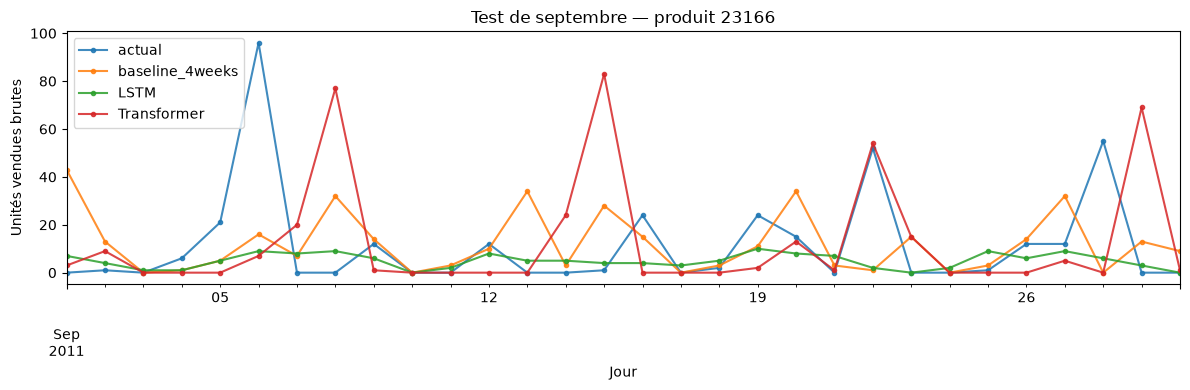

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,84077,144,84,25,21
2011-09-02,84077,48,72,19,56
2011-09-03,84077,0,0,1,0
2011-09-04,84077,96,36,17,32
2011-09-05,84077,144,72,37,0


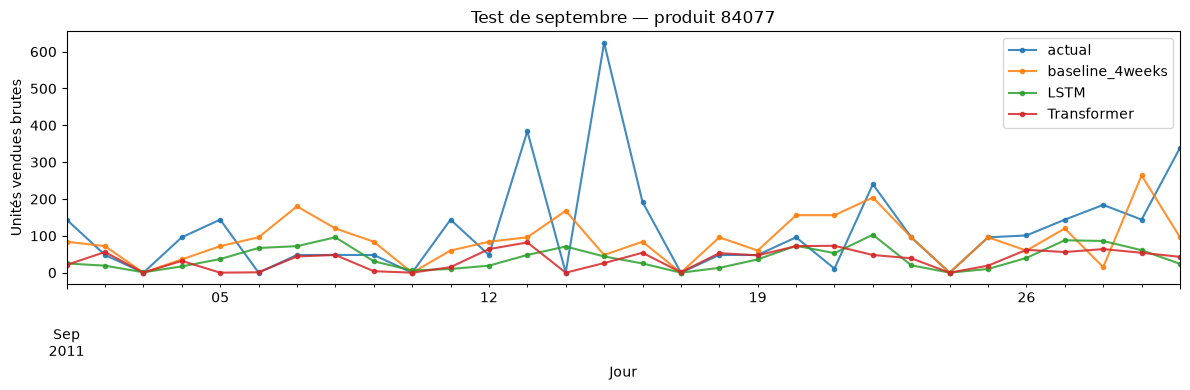

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,85123A,112,78,40,87
2011-09-02,85123A,166,24,18,66
2011-09-03,85123A,0,0,0,0
2011-09-04,85123A,16,50,22,39
2011-09-05,85123A,95,149,41,23


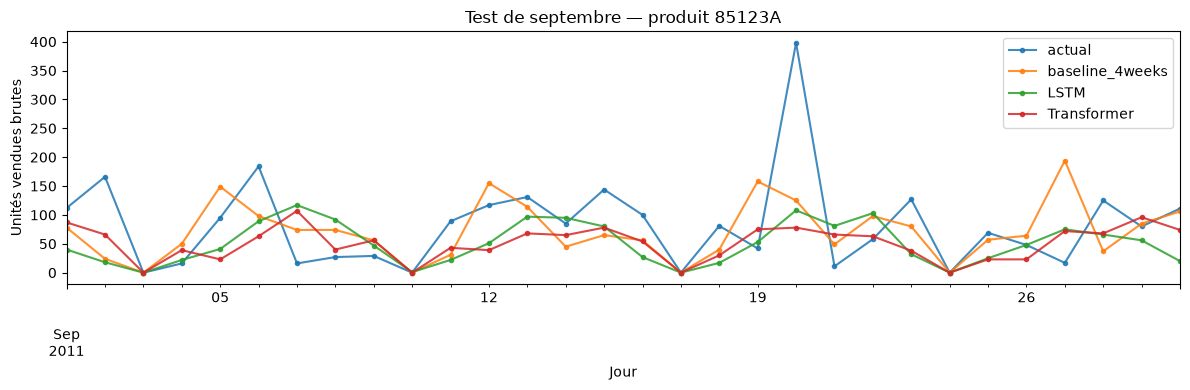

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,85099B,301,274,92,159
2011-09-02,85099B,153,78,30,94
2011-09-03,85099B,0,0,1,0
2011-09-04,85099B,58,134,23,26
2011-09-05,85099B,54,138,48,55


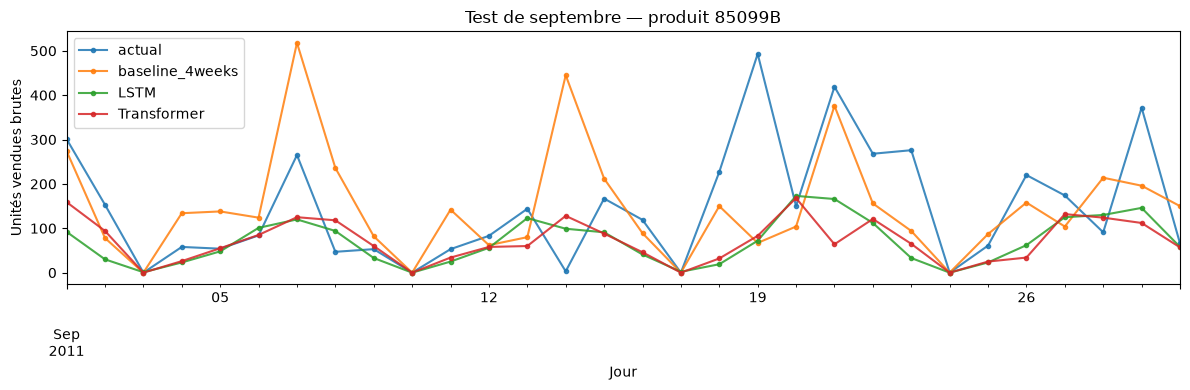

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,22197,101,700,44,76
2011-09-02,22197,667,233,32,59
2011-09-03,22197,0,0,3,0
2011-09-04,22197,24,24,15,22
2011-09-05,22197,105,98,43,91


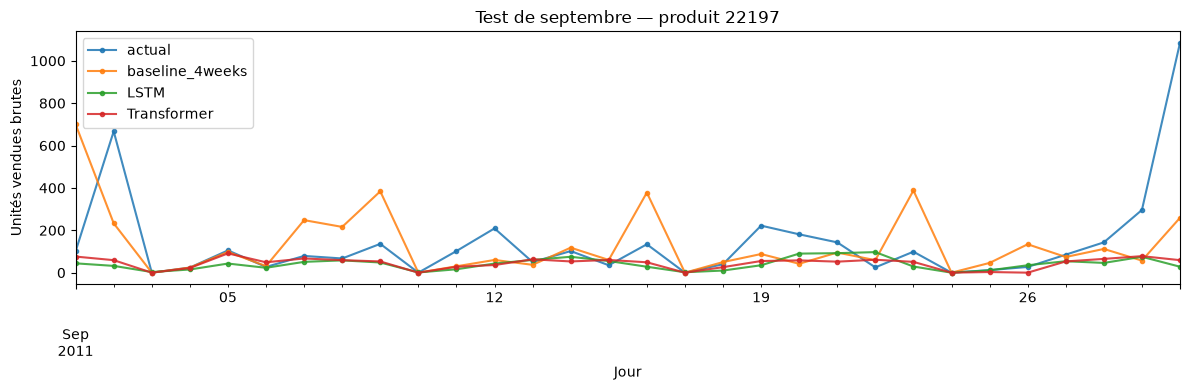

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,21212,75,404,39,65
2011-09-02,21212,229,93,43,88
2011-09-03,21212,0,0,7,0
2011-09-04,21212,79,10,5,29
2011-09-05,21212,156,50,21,40


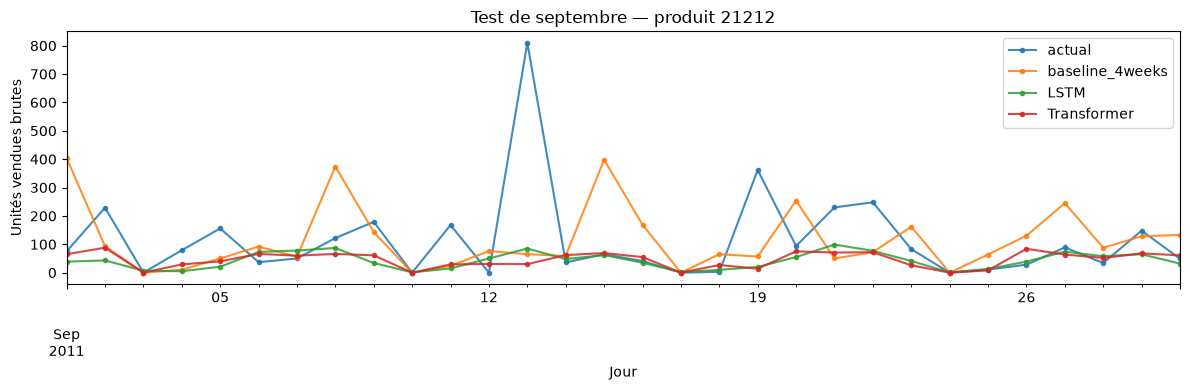

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,84879,96,1216,28,64
2011-09-02,84879,16,96,27,66
2011-09-03,84879,0,0,0,0
2011-09-04,84879,80,78,20,32
2011-09-05,84879,48,100,41,51


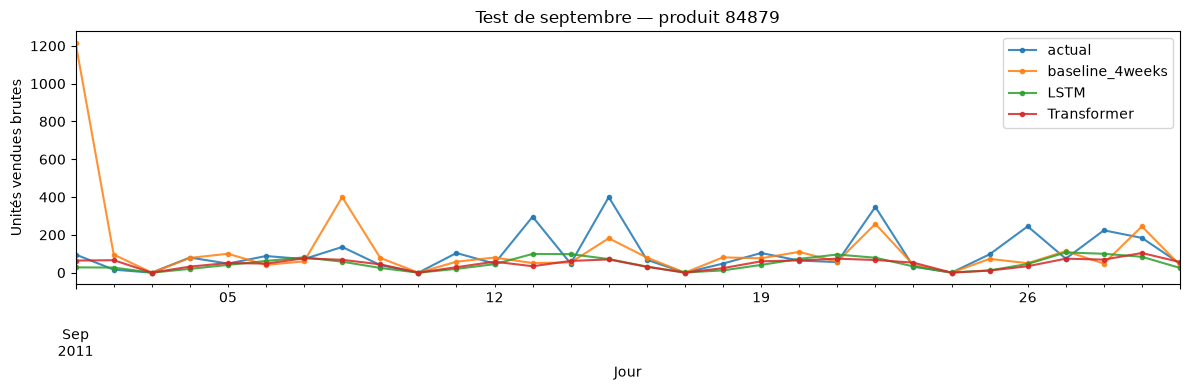

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,15036,48,207,18,33
2011-09-02,15036,13,66,11,45
2011-09-03,15036,0,0,1,0
2011-09-04,15036,24,15,5,38
2011-09-05,15036,0,4,16,19


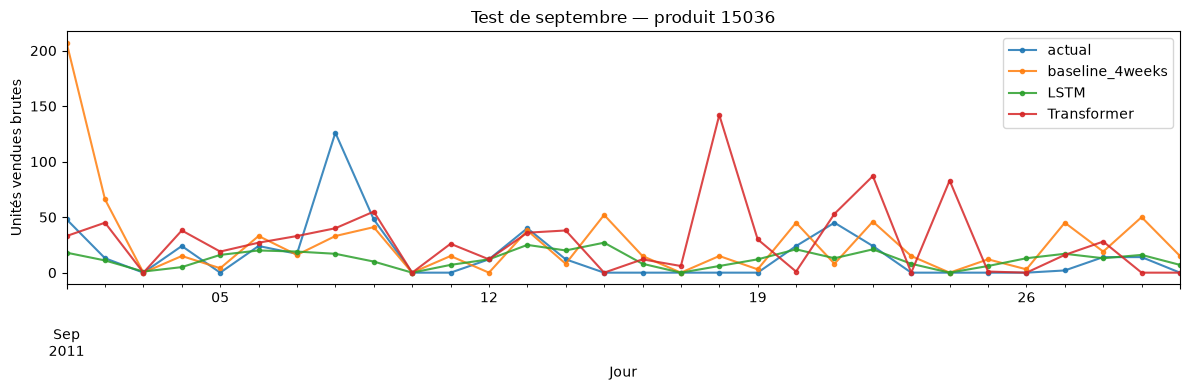

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,22616,456,274,13,25
2011-09-02,22616,0,20,26,0
2011-09-03,22616,0,0,0,0
2011-09-04,22616,0,2,3,1
2011-09-05,22616,2,19,5,35


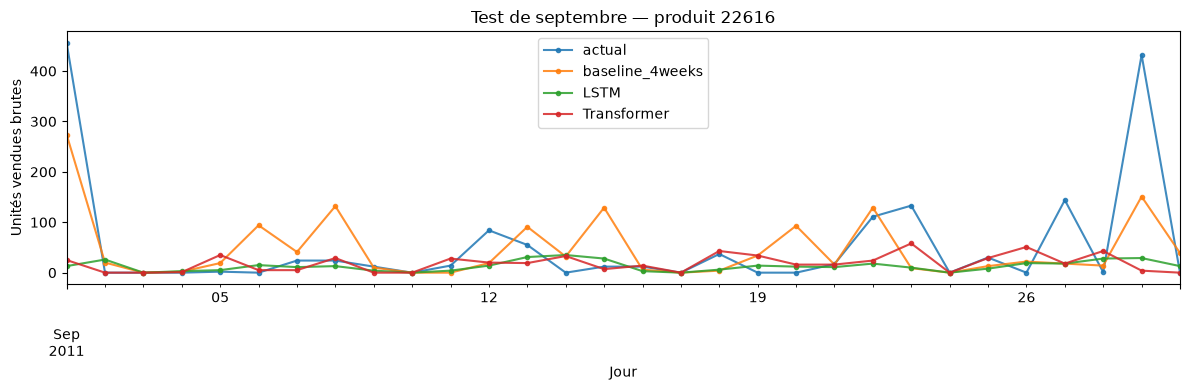

,StockCode,actual,baseline_4weeks,LSTM,Transformer
day,,,,,
2011-09-01,21977,48,222,8,36
2011-09-02,21977,147,18,8,0
2011-09-03,21977,0,0,0,0
2011-09-04,21977,1,16,7,0
2011-09-05,21977,49,13,16,55


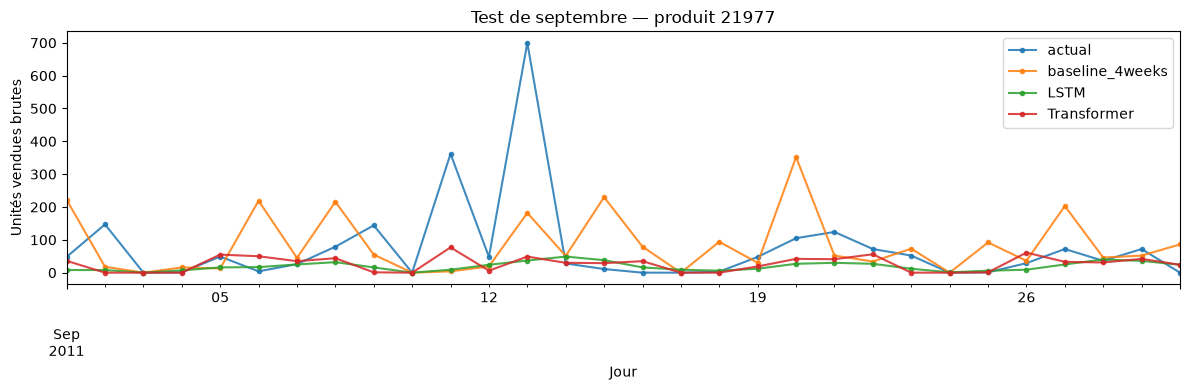

,StockCode,méthode,MAE_unités,RMSE_unités,nombre_prévisions
0,23166,baseline_4weeks,15.933,25.025,30
1,23166,LSTM,11.200,21.528,30
2,23166,Transformer,18.867,32.478,30
3,84077,baseline_4weeks,90.333,146.250,30
4,84077,LSTM,94.600,152.708,30
5,84077,Transformer,87.433,152.381,30
6,85123A,baseline_4weeks,53.867,79.248,30
7,85123A,LSTM,57.500,80.674,30
8,85123A,Transformer,52.667,78.930,30
9,85099B,baseline_4weeks,96.367,145.112,30


In [46]:
per_product_metrics = []
for product in selected_products:
    one_product = (
        validation_results[validation_results["StockCode"].eq(product)]
        .sort_values("day")
        .set_index("day")
    )
    display(one_product.head())
    one_product[["actual", "baseline_4weeks", "LSTM", "Transformer"]].plot(
        figsize=(12, 4), marker=".", alpha=0.85
    )
    plt.title(f"Test de septembre — produit {product}")
    plt.ylabel("Unités vendues brutes")
    plt.xlabel("Jour")
    plt.tight_layout()
    plt.show()

    for method in prediction_columns:
        errors = one_product[method].to_numpy(dtype=float) - one_product["actual"].to_numpy(dtype=float)
        per_product_metrics.append({
            "StockCode": product,
            "méthode": method,
            "MAE_unités": np.mean(np.abs(errors)),
            "RMSE_unités": np.sqrt(np.mean(errors ** 2)),
            "nombre_prévisions": len(errors),
        })

display(pd.DataFrame(per_product_metrics).round(3))

-  On observe que le graphique 1 qui décrit la quantité de vente pour le produit de référence 23166, il y a quelques pics mais le modèle transformer en effet prédit avec aussi des pics mais pas au bon moment, on peut dire que les pics sont assez régulier pour ce produits et donc le transformer a appris ces pics mais ils sont irrégulier, et ils n'arrivent pas au même moment dans les données futures jamais vu.

-  Pour le reste des graphiques des autres produits, on peut voir que les transformers et lstm ont plus de mal à faire des prédictions de pics et les variations, augmentations et diminutions sont assez faibles même si elles sont présentes.

## 11. Analysons l'évolution de la quantité de vente pour toute la période afin de voir si il y a une règle ou une logique dans les courbes.

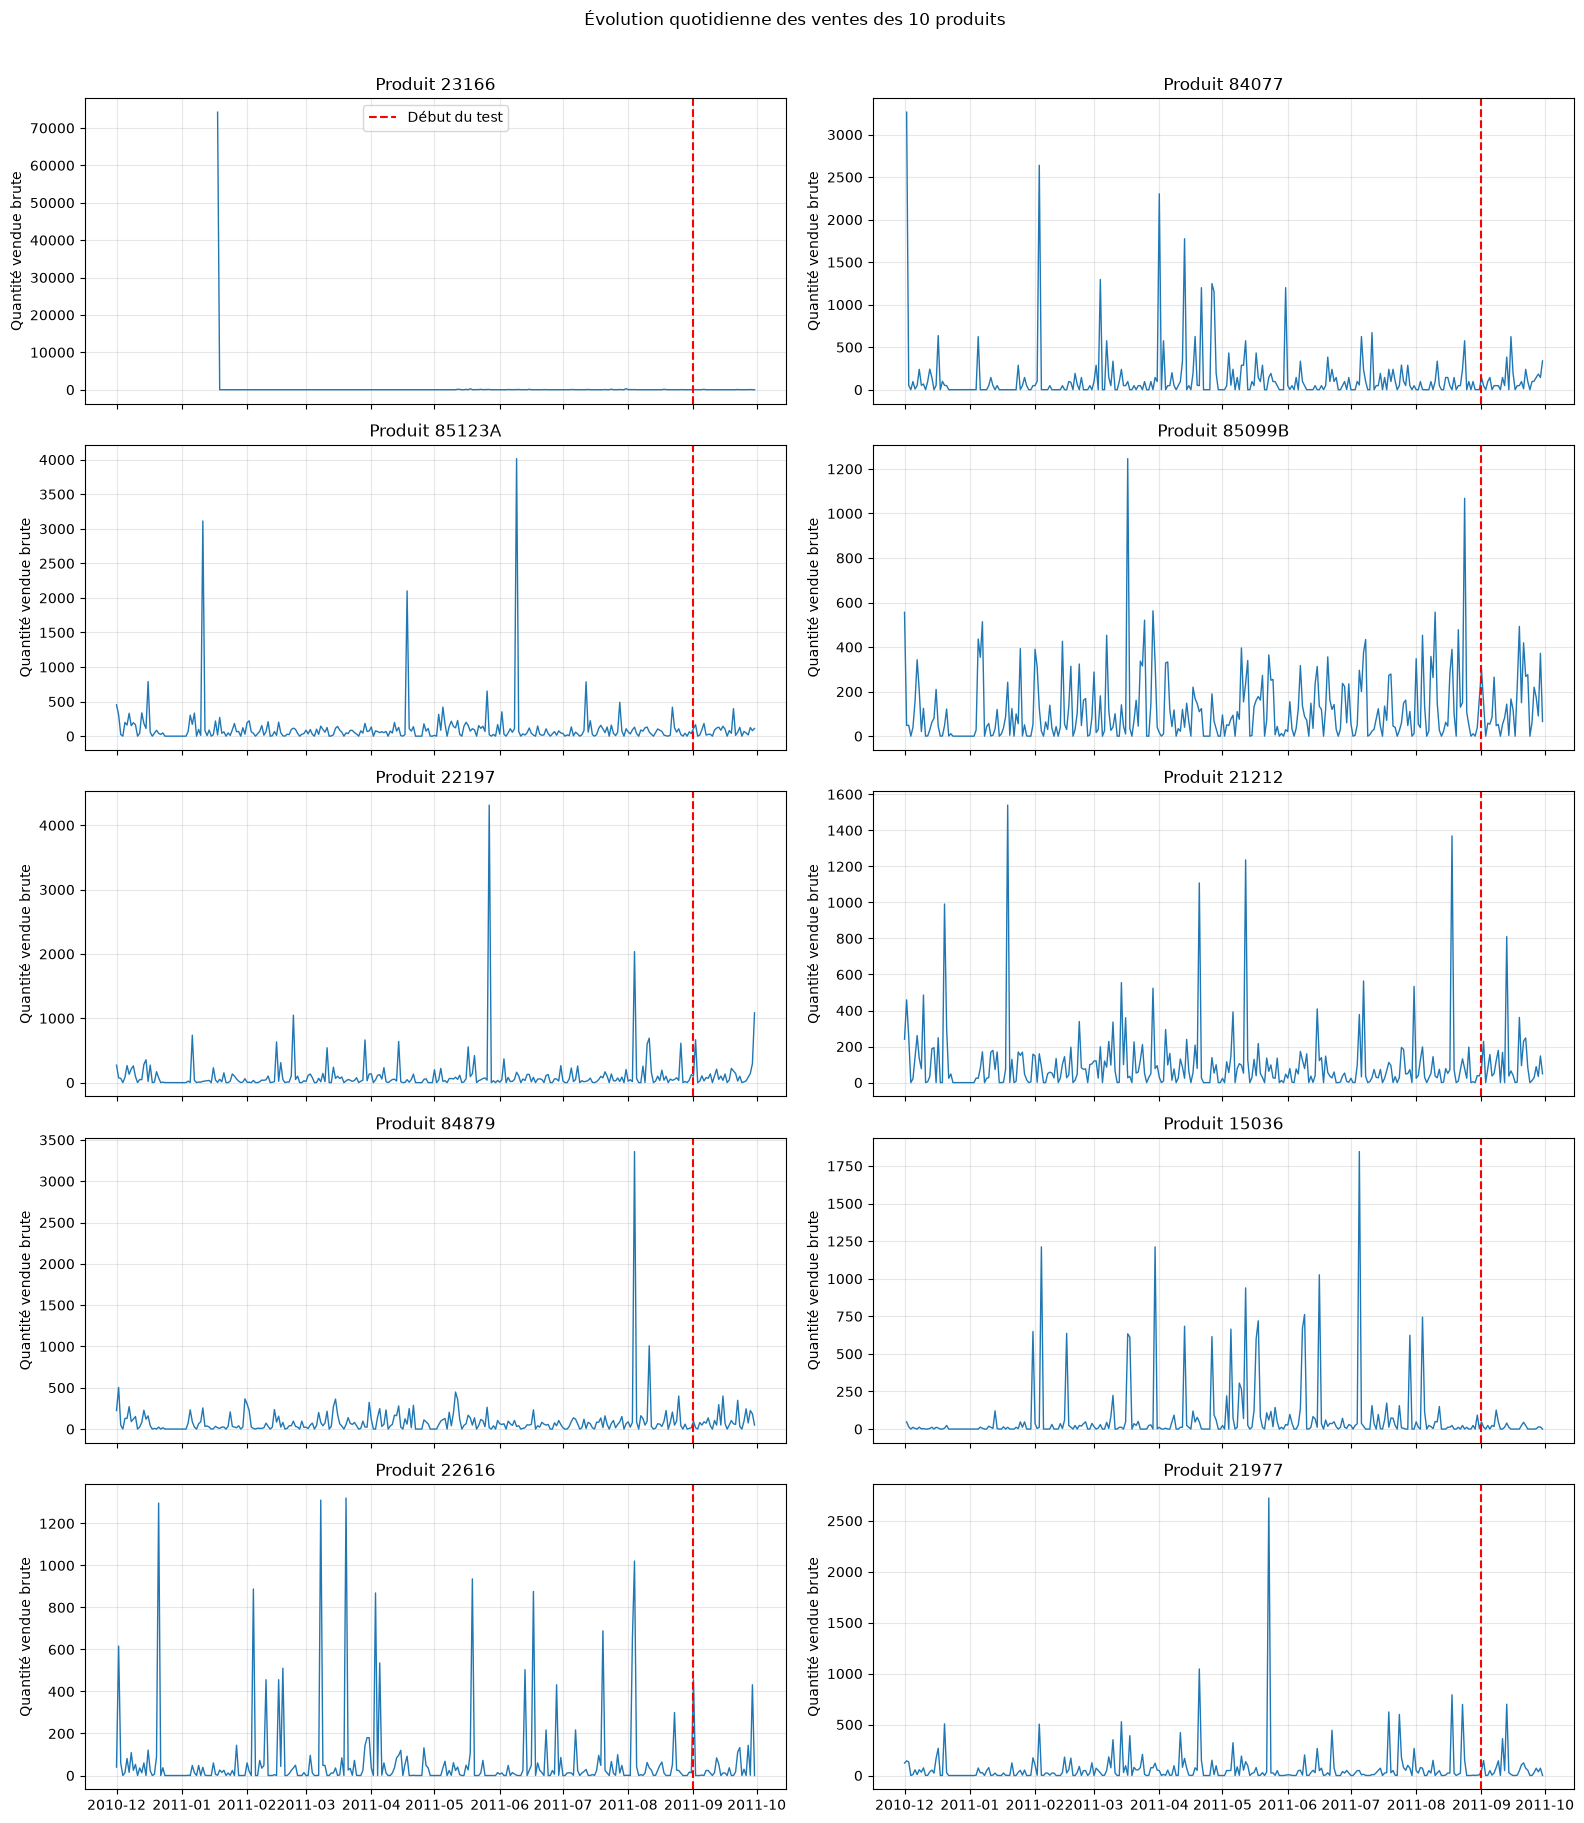

In [34]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18), sharex=True)
axes = axes.ravel()

for ax, product in zip(axes, selected_products):
    values = history_by_product[product]
    ax.plot(values.index, values.values, linewidth=1)
    ax.axvline(pd.Timestamp("2011-09-01"), color="red", linestyle="--",
               label="Début du test")
    ax.set_title(f"Produit {product}")
    ax.set_ylabel("Quantité vendue brute")
    ax.grid(True, alpha=0.3)

axes[0].legend()
fig.suptitle("Évolution quotidienne des ventes des 10 produits", y=1.01)
fig.tight_layout()
plt.show()

- Le dernier graphique montre les ventes brutes quotidiennes des dix produits, du début de leur historique jusqu’au 30 septembre 2011. Chaque sous-graphique correspond à un produit ; la ligne rouge marque le début du test, le 1er septembre.

- La tendance générale est très irrégulière : les ventes alternent entre des jours sans vente et des pics ponctuels. On ne voit pas une hausse régulière qui permettrait de prévoir simplement les ventes à partir d’une tendance. Certains produits semblent avoir des ventes plus fréquentes, tandis que d’autres ont surtout quelques fortes commandes isolées. L'évolution des ventes (ou le marché) semble être imprévisible.